# Módulo 3.1: Mineração de Dados — O Pipeline de ETL e Higienização Inicial

> **Resumo Didático Integrado** — Baseado no *Capítulo 2 (Mineração de Dados — ETL & Limpeza com CEPAGRI)*.

## 1. Visão Geral do Ciclo ETL (Extract, Transform, Load)

Na vida real, mais de 70% a 80% do tempo de um projeto de Ciência de Dados é consumido preparando dados brutos. O processo de **ETL** é composto por três etapas interconectadas:

1. **Extração (*Extract*)**: Ingestão de dados provenientes de fontes heterogêneas (arquivos CSV sem formatação padrão, dumps compactados, APIs, logs de sensores ou bancos transacionais).
2. **Transformação (*Transform*)**:
   * *Diagnóstico e Sanitização*: Ajuste de nomes de colunas, detecção de delimitadores (`sep`), conversão de codificações e eliminação de caracteres inválidos.
   * *Coerção de Tipos*: Transformação de cadeias de texto (`character`) para variáveis analíticas (`numeric`, `Date`, `POSIXct`).
   * *Tratamento de Falhas Físicas*: Identificação de valores de erro de sensor (como o código sentinela `99.9` ou umidade `0%`).
   * *Engenharia de Recursos (*Feature Engineering*)*: Derivação de novos atributos a partir de fórmulas matemáticas ou temporais (ex.: extração de ano, mês, hora e sensação térmica).
3. **Carga (*Load*)**: Exportação dos dados higienizados para arquivos eficientes de consumo analítico (`.csv` formatado ou `.RData` nativo).


## 2. Passo a Passo do Pipeline ETL (Estudo de Caso CEPAGRI)

Aplicaremos a metodologia didática:
* 🎯 **O que fazer**
* 💻 **Como fazer**
* 💡 **Por que fazer**

### Passo 1: Preparação do Ambiente e Ingestão de Dados Brutos (Extração)

🎯 **O que fazer**:
Limpar a sessão, configurar o canvas gráfico e carregar a base bruta do CEPAGRI (`datasets/cepagri.csv`), que não possui cabeçalho e utiliza ponto-e-vírgula (`;`) como separador.

💻 **Como fazer**:

In [1]:
# Limpeza do ambiente de trabalho
rm(list = ls())

# Configuração do tamanho de gráficos no Jupyter
if (requireNamespace("repr", quietly = TRUE)) {
  options(repr.plot.width = 11, repr.plot.height = 5)
}

# Localização do arquivo de dados (compatível tanto na raiz quanto na pasta resumos)
caminho_dados <- if (file.exists("../datasets/cepagri.csv")) {
  "../datasets/cepagri.csv"
} else if (file.exists("datasets/cepagri.csv")) {
  "datasets/cepagri.csv"
} else {
  stop("Arquivo cepagri.csv não encontrado!")
}

# Leitura dos dados brutos:
# header = FALSE (não há linha de cabeçalho no arquivo original)
# sep = ";" (delimitador entre as colunas)
# stringsAsFactors = FALSE (evita que strings sejam lidas como fatores inalteráveis)
dados_brutos <- read.csv(caminho_dados, header = FALSE, sep = ";", stringsAsFactors = FALSE)

# Atribuindo nomes legíveis e padronizados para as 5 colunas
names(dados_brutos) <- c("horario", "temperatura", "vento", "umidade", "sensacao")

cat("Arquivo carregado com sucesso! Dimensões brutas:\n")
cat("Linhas:", nrow(dados_brutos), "| Colunas:", ncol(dados_brutos), "\n\n")
print(head(dados_brutos, 4))

Arquivo carregado com sucesso! Dimensões brutas:
Linhas: 589114 | Colunas: 5 

           horario temperatura vento umidade sensacao
1 02/03/2014-19:08        23.7  59.3    77.1     22.6
2 02/03/2014-19:18        23.4  59.1    77.9     22.3
3 02/03/2014-19:28        23.2  56.7    78.9     22.1
4 02/03/2014-19:38        23.0  55.4    79.2     21.9


💡 **Por que fazer**:
Bases geradas por sensores legados raramente incluem cabeçalhos padronizados. Especificar `header = FALSE` e nomear as variáveis manualmente evita que a primeira linha de dados reais seja descartada como nome de coluna, além de padronizar a nomenclatura para o restante do código.

### Passo 2: Inspeção Estrutural e Coerção Segura de Tipos (Transformação - Parte 1)

🎯 **O que fazer**:
Verificar se todas as colunas numéricas foram corretamente identificadas pelo R ou se há sujeiras textuais forçando a leitura como `character`. Em seguida, converter com segurança para valores numéricos e data/hora.

💻 **Como fazer**:

In [2]:
# Verificando os tipos de cada coluna
print("Estrutura inicial das variáveis:")
str(dados_brutos)

# Criando cópia de trabalho para as transformações
df_clima <- dados_brutos

# 1. Coerção das variáveis de medição climática para numérico
# Caso exista texto inválido inserido por ruído de sensor, o R o converterá para NA emitindo aviso
df_clima$temperatura <- as.numeric(as.character(df_clima$temperatura))
df_clima$vento       <- as.numeric(as.character(df_clima$vento))
df_clima$umidade     <- as.numeric(as.character(df_clima$umidade))
df_clima$sensacao    <- as.numeric(as.character(df_clima$sensacao))

# 2. Conversão da coluna 'horario' para objeto temporal nativo (POSIXct)
# Formato original no arquivo: 'DD/MM/AAAA-HH:MM' (ex: '02/03/2014-19:08')
df_clima$data_hora <- as.POSIXct(df_clima$horario, format = "%d/%m/%Y-%H:%M")

# 3. Engenharia de Recursos Temporais: extraindo hora, mês e ano
df_clima$hora <- as.integer(format(df_clima$data_hora, "%H"))
df_clima$mes  <- as.integer(format(df_clima$data_hora, "%m"))
df_clima$ano  <- as.integer(format(df_clima$data_hora, "%Y"))

print("\nEstrutura após coerção e engenharia temporal:")
str(df_clima[, c("data_hora", "temperatura", "vento", "umidade", "sensacao", "hora")])

[1] "Estrutura inicial das variáveis:"
'data.frame':	589114 obs. of  5 variables:
 $ horario    : chr  "02/03/2014-19:08" "02/03/2014-19:18" "02/03/2014-19:28" "02/03/2014-19:38" ...
 $ temperatura: chr  "23.7" "23.4" "23.2" "23.0" ...
 $ vento      : num  59.3 59.1 56.7 55.4 52.6 62.6 57.4 63.1 59.5 57.1 ...
 $ umidade    : num  77.1 77.9 78.9 79.2 79.7 80.7 81.2 80.6 80.7 81.8 ...
 $ sensacao   : num  22.6 22.3 22.1 21.9 21.7 21.5 21.3 21.2 21 20.7 ...


Warning message:
“NAs introduzidos por coerção”


[1] "\nEstrutura após coerção e engenharia temporal:"
'data.frame':	589114 obs. of  6 variables:
 $ data_hora  : POSIXct, format: "2014-03-02 19:08:00" "2014-03-02 19:18:00" ...
 $ temperatura: num  23.7 23.4 23.2 23 22.8 22.6 22.4 22.3 22.1 21.8 ...
 $ vento      : num  59.3 59.1 56.7 55.4 52.6 62.6 57.4 63.1 59.5 57.1 ...
 $ umidade    : num  77.1 77.9 78.9 79.2 79.7 80.7 81.2 80.6 80.7 81.8 ...
 $ sensacao   : num  22.6 22.3 22.1 21.9 21.7 21.5 21.3 21.2 21 20.7 ...
 $ hora       : int  19 19 19 19 19 19 20 20 20 20 ...


💡 **Por que fazer**:
Se uma única linha contiver um caractere como `[ERRO]` ou `NULL`, o R interpreta toda a coluna como texto (`character`). Sem a conversão explícita para `numeric`, operações matemáticas (média, desvio, correlação) falham. Além disso, estruturar a data em formato `POSIXct` permite filtros temporais e análises de sazonalidade.

### Passo 3: Tratamento de Sentinelas de Erro e Imputação Local (Transformação - Parte 2)

🎯 **O que fazer**:
Identificar valores sentinela específicos da estação meteorológica (ex.: sensação térmica codificada como `99.9` quando há falha de cálculo) e tratá-los utilizando **imputação por janela deslizante local** (média das medições vizinhas válidas no tempo).

💻 **Como fazer**:

In [3]:
# 1. Identificando índices onde a sensação térmica é uma sentinela de erro (acima de 60)
indices_erro_sensacao <- which(df_clima$sensacao > 60)
cat("Quantidade de registros com valor exorbitante (acima de 60):", length(indices_erro_sensacao), "\n")

# Exemplo de tratamento por média local móvel:
# Para cada linha com erro, usamos a média dos 3 registros anteriores e 3 posteriores válidos
for (idx in indices_erro_sensacao) {
  # Garantir que a janela esteja dentro dos limites do DataFrame
  if (idx > 3 && idx < (nrow(df_clima) - 3)) {
    vizinhos <- df_clima$sensacao[(idx - 3):(idx + 3)]
  } else if (idx > 2 && idx < (nrow(df_clima) - 2)) {
    vizinhos <- df_clima$sensacao[(idx - 2):(idx + 2)]
  } else if (idx > 1 && idx < (nrow(df_clima) - 1)) {
    vizinhos <- df_clima$sensacao[(idx - 1):(idx + 1)]
  } else if (idx == 1) {
    vizinhos <- df_clima$sensacao[idx:(idx + 3)]
  } else if (idx == (nrow(df_clima))) {
    vizinhos <- df_clima$sensacao[(idx - 3):idx]
  }

  vizinhos_validos <- vizinhos[vizinhos < 60]
  if (length(vizinhos_validos) > 0) {
    df_clima$sensacao[idx] <- mean(vizinhos_validos)
  }
}

# Para quaisquer outros casos de erro restantes em grande volume:
df_clima$sensacao[df_clima$sensacao > 60] <- NA

# 2. Tratamento de umidade física impossível (ex: sensores registrando 0% em Campinas)
indices_umid_zero <- which(df_clima$umidade <= 0)
cat("Registros com umidade nula física (erro de sensor):", length(indices_umid_zero), "\n")
df_clima$umidade[df_clima$umidade <= 0] <- NA

cat("Tratamento de sentinelas concluído com sucesso!\n")

Quantidade de registros com valor exorbitante (acima de 60): 142 


Registros com umidade nula física (erro de sensor): 15496 
Tratamento de sentinelas concluído com sucesso!


💡 **Por que fazer**:
Estações meteorológicas antigas frequentemente gravam números como `99.9` ou `-999` para sinalizar leitura indisponível. Se mantidos na base, esses valores contaminam drasticamente as métricas (uma sensação térmica de 99,9°C distorceria qualquer média climática). Em séries temporais de alta frequência (leituras a cada 10 minutos), a imputação local pelos vizinhos preserva a continuidade da série sem introduzir ruído.

In [4]:
temp <- df_clima[!is.na(df_clima$temperatura) & df_clima$temperatura < 0, ]
temp

,horario,temperatura,vento,umidade,sensacao,data_hora,hora,mes,ano
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dttm>,<int>,<int>,<int>
522349,26/03/2024-15:00,-7999,13.6,NA,NA,2024-03-26 15:00:00,15,3,2024
522350,26/03/2024-15:10,-7999,13.6,NA,NA,2024-03-26 15:10:00,15,3,2024
522351,26/03/2024-15:20,-7999,13.6,NA,NA,2024-03-26 15:20:00,15,3,2024
522352,26/03/2024-15:30,-7999,13.6,NA,NA,2024-03-26 15:30:00,15,3,2024
522353,26/03/2024-15:40,-7999,13.6,NA,NA,2024-03-26 15:40:00,15,3,2024
522354,26/03/2024-15:50,-7999,13.6,NA,NA,2024-03-26 15:50:00,15,3,2024
522355,26/03/2024-16:00,-7999,13.6,NA,NA,2024-03-26 16:00:00,16,3,2024
522356,26/03/2024-16:10,-7999,13.6,NA,NA,2024-03-26 16:10:00,16,3,2024
522357,26/03/2024-16:20,-7999,13.6,NA,NA,2024-03-26 16:20:00,16,3,2024


In [5]:
df_clima$temperatura[!is.na(df_clima$temperatura) & df_clima$temperatura < 0] <- NA
print(df_clima$temperatura[!is.na(df_clima$temperatura) & df_clima$temperatura < 0])

numeric(0)


In [6]:
summary(df_clima)

      horario        temperatura        vento          umidade      
 Length   :589114   Min.   : 4.10   Min.   :  0.0   Min.   :  5.70  
 N.unique :589015   1st Qu.:18.60   1st Qu.:  8.6   1st Qu.: 56.40  
 N.blank  :     0   Median :21.50   Median : 17.3   Median : 72.50  
 Min.nchar:    16   Mean   :22.03   Mean   : 21.0   Mean   : 69.29  
 Max.nchar:    16   3rd Qu.:25.60   3rd Qu.: 28.8   3rd Qu.: 83.60  
                    Max.   :38.10   Max.   :143.6   Max.   :100.00  
                    NAs    :47093   NAs    :47084   NAs    :62580   
    sensacao        data_hora                        hora      
 Min.   :-8.20    Min.   :2014-03-02 19:08:00   Min.   : 0.00  
 1st Qu.:16.60    1st Qu.:2017-01-09 23:32:30   1st Qu.: 6.00  
 Median :19.90    Median :2019-11-05 17:55:00   Median :12.00  
 Mean   :19.83    Mean   :2019-11-11 02:51:27   Mean   :11.52  
 3rd Qu.:23.90    3rd Qu.:2022-09-09 20:47:30   3rd Qu.:18.00  
 Max.   :34.70    Max.   :2025-08-05 18:20:00   Max.   :23.00  


### Passo 4: Diagnóstico Visual e Validação do Saneamento

🎯 **O que fazer**:
Validar graficamente a higienização dos dados através de histogramas e boxplots das variáveis limpas.

💻 **Como fazer**:

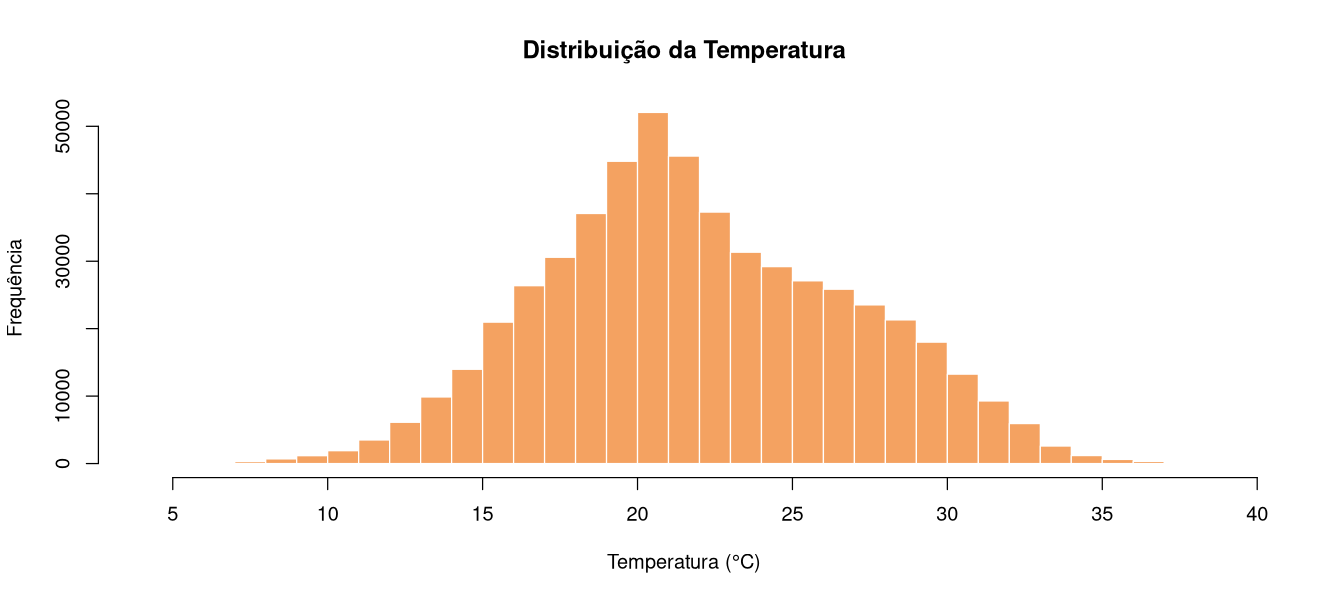

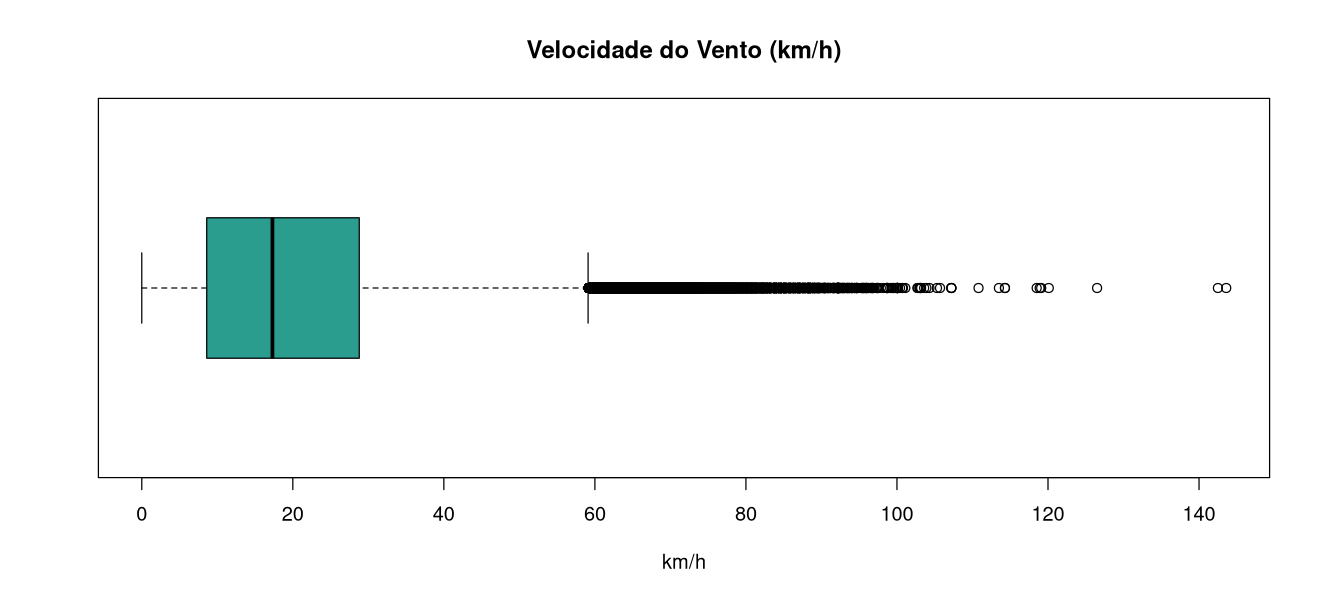

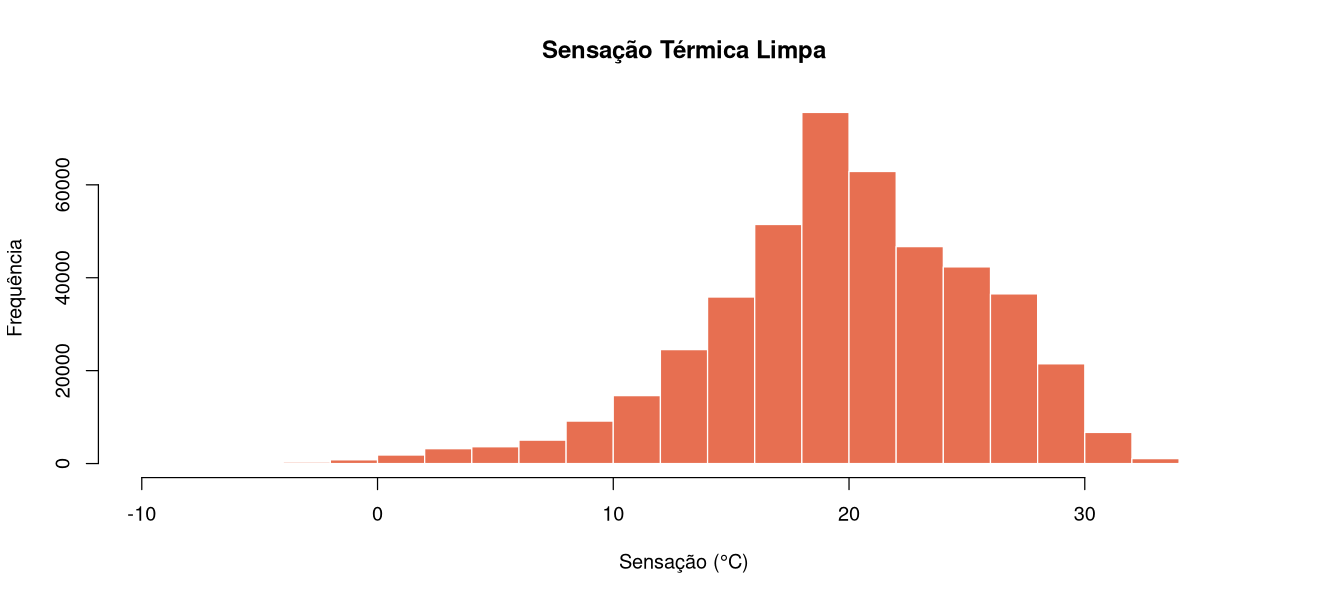

In [7]:
# Histograma da Temperatura
hist(df_clima$temperatura[!is.na(df_clima$temperatura)], breaks = 30, col = "#f4a261", border = "white",
     main = "Distribuição da Temperatura", xlab = "Temperatura (°C)", ylab = "Frequência")

# Boxplot da Velocidade do Vento
boxplot(df_clima$vento, horizontal = TRUE, col = "#2a9d8f",
        main = "Velocidade do Vento (km/h)", xlab = "km/h")

# Histograma da Sensação Térmica Higienizada
hist(df_clima$sensacao[!is.na(df_clima$sensacao)], breaks = 30, col = "#e76f51", border = "white",
     main = "Sensação Térmica Limpa", xlab = "Sensação (°C)", ylab = "Frequência")

💡 **Por que fazer**:
A validação visual é o teste final de integridade de um processo de ETL. O desaparecimento de barras anômalas no extremo direito (como o pico em 99.9) confirma que a base está estatisticamente coerente e pronta para modelagem.

### Passo 5: Carga e Persistência Otimizada (Carga)

🎯 **O que fazer**:
Exportar o dataset final limpo para um arquivo CSV estruturado e para um arquivo `.RData` de alta densidade e carregamento instantâneo.

💻 **Como fazer**:

In [8]:
# Criando DataFrame com as variáveis limpas essenciais
cepagri_higienizado <- df_clima[, c("data_hora", "ano", "mes", "hora", "temperatura", "vento", "umidade", "sensacao")]

# 1. Exportando para CSV (portabilidade externa)
write.csv(head(cepagri_higienizado, 1000), file = "cepagri_amostra_limpa.csv", row.names = FALSE)

# 2. Salvando no formato nativo RData (desempenho e fidelidade de tipos)
save(cepagri_higienizado, file = "cepagri_higienizado.RData")

cat("Arquivos de saída gerados com sucesso:\n")
cat("- cepagri_amostra_limpa.csv (portável para qualquer software)\n")
cat("- cepagri_higienizado.RData (carregamento instantâneo com classes preservadas)\n")

Arquivos de saída gerados com sucesso:
- cepagri_amostra_limpa.csv (portável para qualquer software)
- cepagri_higienizado.RData (carregamento instantâneo com classes preservadas)


💡 **Por que fazer**:
Arquivos CSV exigem que o R processe novamente todo o parsing de texto e datas a cada leitura. Já o formato `.RData` comprime os dados em nível binário e restaura instantaneamente os tipos `POSIXct` e `numeric` exatos com uma simples chamada `load()`, economizando tempo e memória em projetos analíticos.

## 3. Conclusão e Próximos Passos
Neste Módulo 3.1, construímos:
* O pipeline completo de **Extração, Transformação e Carga (ETL)**.
* Técnicas de leitura para dados não convencionais (`sep = ";"`, sem cabeçalho).
* Tratamento de códigos sentinela (`99.9`) via imputação por janela móvel.
* Exportação eficiente em `.csv` e `.RData`.

No **Módulo 3.2 (`03_2_Mineracao_Dados_Qualidade_Tratamento_Avancado.ipynb`)**, completaremos o ciclo de mineração avançando para **detecção estatística de Outliers via IQR**, **imputação multidimensional de NAs** e **harmonização textual massiva de texto livre com Regex** (pesquisa salarial e base imobiliária de King County).